# Fútbol femenino: rendimiento observado y EA Sports FC24
## 1. Introducción y pregunta de investigación
¿Hasta qué punto las valoraciones de EA Sports FC24 se corresponden con el rendimiento deportivo observado de las futbolistas, teniendo en cuenta su posición, liga y participación?

Hipótesis exploratorias: puede existir una asociación positiva entre valoración y algunas métricas de la misma posición; su intensidad puede variar por liga y participación.

## 2. Fuentes de datos y alcance
Utilizamos `jugadoras_deporte_ampliado.csv`, preparado con StatsBomb Open Data, y los nombres de `jugadoras_total_limpio.csv`. El notebook anterior es EDA_FINAL.ipynb. El trabajo previo informa de 771 partidos procesados.

`position` contiene intervalos anidados. Las categorías son Forward, Midfielder, Defender y Goalkeeper.

Ligas: Liga F, FA Women's Super League, Frauen Bundesliga y Serie A Women (2023/2024), y NWSL (2023). Unidad: jugadora–equipo–liga–temporada.

FC24: [dataset de Stefano Leone en Kaggle](https://www.kaggle.com/datasets/stefanoleone992/ea-sports-fc-24-complete-player-dataset), copia local filtrada a edición 24. Los atributos son evaluaciones del videojuego. 

In [1]:
from pathlib import Path
Path("data/procesados").mkdir(parents=True, exist_ok=True)
Path("figuras").mkdir(exist_ok=True)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 35)
jugadoras = pd.read_csv("data/originales/jugadoras_total_limpio.csv")
informe = pd.read_csv("data/originales/informe_position.csv")
deporte = pd.read_csv("data/originales/jugadoras_deporte_ampliado.csv")
fc_original = pd.read_csv("data/originales/fc24_jugadoras_2023_09_22.csv")
preliminar = pd.read_csv("data/originales/candidatas_cruce_fc24_por_nombre.csv")

## 3. Carga y revisión inicial
Filas, IDs, tipos, ausentes y claves. No confundimos filas repetidas por jugadora con duplicados de la unidad de análisis.

In [2]:
for nombre, tabla in [("Nombres", jugadoras), ("Deporte", deporte), ("FC24", fc_original)]:
    print(nombre, tabla.shape, "IDs únicos:", tabla["player_id"].nunique(), "duplicados completos:", tabla.duplicated().sum())
    display(pd.DataFrame({"tipo": tabla.dtypes, "ausentes": tabla.isna().sum()}))
    display(tabla.head(3))
clave = ["player_id", "team", "league", "season"]
print("Duplicados de clave deportiva:", deporte.duplicated(clave).sum())
display(deporte.groupby(["league", "season"]).agg(filas=("player_id", "size"), jugadoras=("player_id", "nunique")))
display(deporte["position"].value_counts(dropna=False))
display(deporte.describe())
display(informe.groupby(["metodo", "estado_verificacion"]).size().reset_index(name="jugadoras"))
assert deporte.duplicated(clave).sum() == 0
assert jugadoras["player_id"].is_unique
assert fc_original["player_id"].is_unique
assert set(fc_original["fifa_version"].dropna()) == {24}
assert fc_original["fifa_version"].notna().all()
display(fc_original[["fifa_version", "update_as_of"]].value_counts())

Nombres (1739, 8) IDs únicos: 1739 duplicados completos: 0


,tipo,ausentes
player_id,int64,0
player_name,str,0
player_nickname,str,1330
jersey_number,int64,0
country,str,0
cards,str,0
positions,str,0
position,str,0


,player_id,player_name,player_nickname,jersey_number,country,cards,positions,position
0,6818,Hayley Emma Raso,Hayley Raso,15,Australia,[],"[{'position_id': 11, 'position': 'Left Defensi...",Forward
1,24460,Signe Kallesøe Bruun,Signe Bruun,9,Denmark,[],"[{'position_id': 22, 'position': 'Right Center...",Forward
2,25556,Kathellen Sousa Feitoza,Kathellen Sousa,14,Brazil,[],"[{'position_id': 5, 'position': 'Left Center B...",Defender


Deporte (1791, 20) IDs únicos: 1739 duplicados completos: 0


,tipo,ausentes
player_id,int64,0
player_name,str,0
country,str,0
position,str,0
team,str,0
league,str,0
season,str,0
tiros,float64,211
goles,float64,211
pases_intentados,float64,211


,player_id,player_name,country,position,team,league,season,tiros,goles,pases_intentados,pases_completados,paradas,partidos_jugados,xg,pases_a_tiro,asistencias,entradas,entradas_favorables,intercepciones,intercepciones_favorables
0,6818,Hayley Emma Raso,Australia,Forward,Real Madrid CF W,Liga F,2023/2024,38.0,4.0,576.0,407.0,NaN,28,5.234703,22.0,1.0,52.0,31.0,21.0,14.0
1,24460,Signe Kallesøe Bruun,Denmark,Forward,Real Madrid CF W,Liga F,2023/2024,55.0,12.0,341.0,233.0,NaN,25,9.321190,15.0,2.0,10.0,7.0,6.0,6.0
2,25556,Kathellen Sousa Feitoza,Brazil,Defender,Real Madrid CF W,Liga F,2023/2024,7.0,1.0,935.0,824.0,NaN,18,1.287157,4.0,0.0,26.0,18.0,16.0,8.0


... (5 outputs left out)

position
Defender      572
Midfielder    529
Forward       470
Goalkeeper    220
Name: count, dtype: int64

,player_id,tiros,goles,pases_intentados,pases_completados,paradas,partidos_jugados,xg,pases_a_tiro,asistencias,entradas,entradas_favorables,intercepciones,intercepciones_favorables
count,1791.000000,1580.000000,1580.000000,1580.000000,1580.000000,140.000000,1791.000000,1580.000000,1580.000000,1580.000000,1580.000000,1580.000000,1580.000000,1580.000000
mean,153140.075935,12.822152,1.451899,452.903165,344.470886,36.750000,13.116695,1.358897,8.664557,0.924051,20.024051,11.812025,10.436076,6.160759
std,155877.058485,15.859201,2.548745,403.016478,329.366600,31.481666,9.075371,2.054641,10.829621,1.554761,19.837961,11.999081,11.522331,6.933374
min,3921.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,31803.500000,1.000000,0.000000,114.000000,78.000000,9.000000,4.000000,0.065560,1.000000,0.000000,3.000000,2.000000,1.000000,1.000000
50%,50821.000000,7.000000,0.000000,358.000000,259.000000,26.500000,14.000000,0.520453,5.000000,0.000000,15.000000,8.000000,6.000000,4.000000
75%,324162.000000,18.000000,2.000000,685.750000,522.000000,60.250000,21.000000,1.694240,13.000000,1.000000,31.000000,18.000000,16.000000,9.000000
max,435464.000000,106.000000,21.000000,2135.000000,1887.000000,108.000000,30.000000,14.826841,90.000000,19.000000,127.000000,76.000000,75.000000,46.000000


,metodo,estado_verificacion,jugadoras
0,Perfil/plantilla — posición general verificada,Posición general documentada,192
1,Posición habitual — desempate con perfil docum...,Posición habitual documentada,6
2,Posición habitual — revisión individual,Identificación probable; revisar país y grafía,1
3,Posición habitual — revisión individual,Posición habitual documentada,10
4,StatsBomb — categoría más frecuente por partidos,Derivada de registros de partido,1530


fifa_version  update_as_of
24.0          2023-09-22      1839
Name: count, dtype: int64

## 4. Preparación de los datos deportivos
Conservamos la base completa. Creamos otra con `partidos_jugados > 0`: son apariciones con participación registrada, **no minutos ni métricas por 90**. No rellenamos ausentes con cero.

xG suma `statsbomb_xg`. Pases a tiro incluye `shot_assist` o `goal_assist`. Entradas incluye duelos Tackle; favorables e intercepciones favorables usan Won, Success, Success In Play y Success Out según el campo. Paradas incluye Shot Saved, Shot Saved Off Target, Shot Saved to Post, Penalty Saved y Penalty Saved to Post; excluye Save. Las paradas se interpretan para porteras.
Precisión de pase y conversión solo se calculan positivos.

In [3]:
deporte = deporte.rename(columns={"player_id": "id_statsbomb"})
deporte_completo = deporte.copy()
activas = deporte[deporte["partidos_jugados"] > 0].copy()
print("Con participación:", len(activas), "Sin participación:", len(deporte) - len(activas))
metricas = ["xg", "tiros", "pases_a_tiro", "asistencias", "entradas_favorables", "intercepciones_favorables", "paradas"]
for metrica in metricas:
    activas[metrica + "_por_aparicion"] = activas[metrica] / activas["partidos_jugados"]
activas.loc[activas["pases_intentados"] > 0, "precision_pase"] = 100 * activas["pases_completados"] / activas["pases_intentados"]
activas.loc[activas["tiros"] > 0, "conversion"] = 100 * activas["goles"] / activas["tiros"]
display(activas[metricas + ["precision_pase", "conversion"]].describe())
display(activas.groupby("position")["paradas"].agg(["count", "size"]))

Con participación: 1580 Sin participación: 211


,xg,tiros,pases_a_tiro,asistencias,entradas_favorables,intercepciones_favorables,paradas,precision_pase,conversion
count,1580.000000,1580.000000,1580.000000,1580.000000,1580.000000,1580.000000,140.000000,1567.000000,1273.000000
mean,1.358897,12.822152,8.664557,0.924051,11.812025,6.160759,36.750000,72.813216,9.384175
std,2.054641,15.859201,10.829621,1.554761,11.999081,6.933374,31.481666,11.875271,12.925280
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.065560,1.000000,1.000000,0.000000,2.000000,1.000000,9.000000,66.666667,0.000000
50%,0.520453,7.000000,5.000000,0.000000,8.000000,4.000000,26.500000,73.684211,6.666667
75%,1.694240,18.000000,13.000000,1.000000,18.000000,9.000000,60.250000,80.432831,14.285714
max,14.826841,106.000000,90.000000,19.000000,76.000000,46.000000,108.000000,100.000000,100.000000


,count,size
position,,
Defender,0,524
Forward,0,445
Goalkeeper,138,138
Midfielder,2,473


## 5. Preparación de FC24 y cruce de jugadoras
Normalizamos nombres en minúsculas, sin tildes, puntuación ni espacios. Se comparan nombre completo y deportivo con long_name y short_name. 
Revisamos clubes en una tabla exportada; no usamos diferencias de club como rechazo automático, porque puede haber traspasos. Los apodos solos, ambigüedades, discrepancias y nombres sin candidato quedan pendientes.

In [4]:
columnas_fc = ["player_id", "short_name", "long_name", "dob", "age", "height_cm", "preferred_foot", "nationality_name", "club_name", "league_name", "player_positions", "overall", "potential", "passing", "defending", "shooting", "pace", "dribbling", "physic"]
columnas_porteras = []
for columna in fc_original.columns:
    if columna.startswith("goalkeeping_"):
        columnas_porteras.append(columna)
print("Atributos de porteras:", columnas_porteras)
fc = fc_original[columnas_fc + columnas_porteras].copy()
fc = fc.rename(columns={"player_id": "id_fc24"})
nombres_sb = jugadoras[["player_id", "player_name", "player_nickname", "country"]].copy()
nombres_sb = nombres_sb.rename(columns={"player_id": "id_statsbomb"})
for columna in ["player_name", "player_nickname"]:
    nombres_sb[columna + "_clave"] = nombres_sb[columna].fillna("").str.lower().str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("ascii").str.replace(r"[^a-z0-9]", "", regex=True)
for columna in ["long_name", "short_name"]:
    fc[columna + "_clave"] = fc[columna].fillna("").str.lower().str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("ascii").str.replace(r"[^a-z0-9]", "", regex=True)
partes = []
for nombre_sb in ["player_name_clave", "player_nickname_clave"]:
    for nombre_fc in ["long_name_clave", "short_name_clave"]:
        izquierda = nombres_sb[nombres_sb[nombre_sb] != ""][["id_statsbomb", nombre_sb]]
        derecha = fc[fc[nombre_fc] != ""][["id_fc24", nombre_fc]]
        parte = izquierda.merge(derecha, left_on=nombre_sb, right_on=nombre_fc)
        partes.append(parte[["id_statsbomb", "id_fc24"]])
candidatas = pd.concat(partes, ignore_index=True).drop_duplicates()
recuento = candidatas.groupby("id_statsbomb").size().reset_index(name="n_candidatos")
candidatas = candidatas.merge(recuento, on="id_statsbomb", validate="many_to_one")
unicas = candidatas[candidatas["n_candidatos"] == 1].copy()
print("IDs con candidato único reconstruido:", len(unicas))
control = unicas.merge(preliminar, left_on=["id_statsbomb", "id_fc24"], right_on=["player_id_statsbomb", "player_id_fc24"], how="outer", indicator=True)
display(control["_merge"].value_counts())
display(deporte.merge(unicas, on="id_statsbomb", how="inner", validate="many_to_one").groupby("league")["id_statsbomb"].nunique())

Atributos de porteras: ['goalkeeping_diving', 'goalkeeping_handling', 'goalkeeping_kicking', 'goalkeeping_positioning', 'goalkeeping_reflexes', 'goalkeeping_speed']
IDs con candidato único reconstruido: 1047


_merge
both          1047
left_only        0
right_only       0
Name: count, dtype: int64

league
FA Women's Super League    217
Frauen Bundesliga          260
Liga F                     305
NWSL                       247
Serie A Women               31
Name: id_statsbomb, dtype: int64

In [5]:
revision = candidatas.merge(nombres_sb, on="id_statsbomb", validate="many_to_one")
revision = revision.merge(fc, on="id_fc24", validate="many_to_one")
equivalencias_pais = {"United States of America": "United States", "Ireland": "Republic of Ireland", "Korea (South)": "Korea Republic", "Venezuela (Bolivarian Republic)": "Venezuela", "Macedonia, Republic of": "North Macedonia", "China": "China PR", "Curaçao": "Curacao"}
revision["pais_sb"] = revision["country"].replace(equivalencias_pais)
revision["pais_coincide"] = revision["pais_sb"] == revision["nationality_name"]
revision["nombre_completo_coincide"] = revision["player_name_clave"] == revision["long_name_clave"]
equivalencias_liga = {"Primera Division Women": "Liga F", "Women's Super League": "FA Women's Super League", "Bundesliga Women": "Frauen Bundesliga", "NWSL": "NWSL", "Serie A Women": "Serie A Women"}
revision["liga_fc_contexto"] = revision["league_name"].map(equivalencias_liga)
contextos = deporte[["id_statsbomb", "league"]].drop_duplicates()
contextos["liga_coincide"] = True
revision = revision.merge(contextos, left_on=["id_statsbomb", "liga_fc_contexto"], right_on=["id_statsbomb", "league"], how="left", validate="many_to_one")
revision["liga_coincide"] = revision["liga_coincide"].eq(True)
revision["id_fc_compartido"] = revision["id_fc24"].duplicated(keep=False)
revision["aceptada_provisional"] = (revision["n_candidatos"] == 1) & revision["pais_coincide"] & revision["nombre_completo_coincide"] & revision["liga_coincide"] & ~revision["id_fc_compartido"]
identidades = revision[revision["aceptada_provisional"]][["id_statsbomb", "id_fc24"]].copy()
assert identidades["id_statsbomb"].is_unique
assert identidades["id_fc24"].is_unique
pendientes = revision[~revision["aceptada_provisional"]].copy()
sin_candidata = nombres_sb[~nombres_sb["id_statsbomb"].isin(candidatas["id_statsbomb"])].copy()
clubes_revision = deporte[["id_statsbomb", "player_name", "team", "league", "season"]].merge(revision[["id_statsbomb", "id_fc24", "club_name", "nationality_name", "pais_coincide", "aceptada_provisional"]], on="id_statsbomb", how="left")
revision.to_csv("data/procesados/revision_identidades.csv", index=False)
pendientes.to_csv("data/procesados/candidatas_pendientes.csv", index=False)
sin_candidata.to_csv("data/procesados/sin_candidata.csv", index=False)
clubes_revision.to_csv("data/procesados/revision_clubes.csv", index=False)
print("Aceptadas provisionalmente:", len(identidades), "Pares pendientes:", len(pendientes), "Sin candidata:", len(sin_candidata))
display(clubes_revision.head(15))
display(pendientes[["player_name", "long_name", "country", "nationality_name", "club_name", "n_candidatos", "nombre_completo_coincide", "liga_coincide"]].head(15))

Aceptadas provisionalmente: 933 Pares pendientes: 116 Sin candidata: 691


,id_statsbomb,player_name,team,league,season,id_fc24,club_name,nationality_name,pais_coincide,aceptada_provisional
0,6818,Hayley Emma Raso,Real Madrid CF W,Liga F,2023/2024,227137.0,Real Madrid W,Australia,True,True
1,24460,Signe Kallesøe Bruun,Real Madrid CF W,Liga F,2023/2024,264946.0,Real Madrid W,Denmark,True,True
2,25556,Kathellen Sousa Feitoza,Real Madrid CF W,Liga F,2023/2024,248800.0,Real Madrid W,Brazil,True,True
3,30961,Naomie Feller,Real Madrid CF W,Liga F,2023/2024,265900.0,Real Madrid W,France,True,True
4,30971,Sandie Toletti,Real Madrid CF W,Liga F,2023/2024,NaN,NaN,NaN,NaN,NaN
5,31820,Mylène Chavas,Real Madrid CF W,Liga F,2023/2024,264865.0,Real Madrid W,France,True,True
6,32211,Kenti Robles Salas,Real Madrid CF W,Liga F,2023/2024,NaN,NaN,NaN,NaN,NaN
7,32225,Caroline Møller Hansen,Real Madrid CF W,Liga F,2023/2024,268992.0,Real Madrid W,Denmark,True,True
8,49830,María Isabel Rodríguez Rivero,Real Madrid CF W,Liga F,2023/2024,258789.0,Real Madrid W,Spain,True,True
9,49831,Ivana Andrés Sanz,Real Madrid CF W,Liga F,2023/2024,227780.0,Real Madrid W,Spain,True,True


,player_name,long_name,country,nationality_name,club_name,n_candidatos,nombre_completo_coincide,liga_coincide
23,Aleksandra Zaremba,Aleksandra Zaremba,Poland,Spain,UDG Tenerife W,1,True,True
81,Bibiane Schulze-Solano,Bibiane Schulze Solano,Germany,Spain,Athletic Bilbao W,1,True,True
140,Dorine Nina Chuigoue,Dorine Nina Chuigoué,Equatorial Guinea,Cameroon,Real Betis W,1,True,True
159,Paula Sancho González,Paula Sancho González,Spain,Spain,Valencia W,2,True,True
185,Anna Margraf,Anna Margraf,Australia,Germany,Huelva W,1,True,True
219,Giovana Queiroz Costa,Giovana Queiroz Costa,Brazil,Brazil,Arsenal W,1,True,False
250,Gia Corley,Gia Corley,Germany,United States,Hoffenheim W,1,True,True
288,Selma Sól Magnúsdóttir,Selma Sól Magnúsdóttir,Iceland,Iceland,NaN,1,True,False
331,Tanja Pawollek,Tanja Pawollek,Poland,Germany,Eintracht Frankfurt W,1,True,True
349,Maja Sternad,Maja Sternad,Slovenia,Germany,Werder Bremen W,1,True,True


## 6. Calidad del dataframe final y variables para comparar
La unión izquierda conserva todas las filas deportivas. `validate` exige una correspondencia muchos-a-uno y se comprueba el tamaño antes y después. 
Las correlaciones principales se restringen a personas con un único contexto para evitar repetir una misma valoración como observación independiente.

In [6]:
enlace = identidades.merge(fc, on="id_fc24", validate="one_to_one")
completa = deporte_completo.merge(enlace, on="id_statsbomb", how="left", validate="many_to_one")
analisis = activas.merge(enlace, on="id_statsbomb", how="inner", validate="many_to_one")
assert len(completa) == len(deporte_completo)
assert completa.duplicated(["id_statsbomb", "team", "league", "season"]).sum() == 0
completa["con_fc24"] = completa["id_fc24"].notna()
for agrupacion in ["league", "position"]:
    cobertura = completa.groupby(agrupacion).agg(filas=("id_statsbomb", "size"), ids=("id_statsbomb", "nunique"), filas_con_fc24=("con_fc24", "sum"))
    cobertura["cobertura_filas_pct"] = 100 * cobertura["filas_con_fc24"] / cobertura["filas"]
    display(cobertura.round(2))
    cobertura.to_csv("data/procesados/cobertura_" + agrupacion + ".csv")
display(completa.isna().sum().sort_values(ascending=False))
completa.to_csv("data/procesados/base_completa.csv", index=False)
analisis.to_csv("data/procesados/base_analisis.csv", index=False)
muestra = analisis[analisis["partidos_jugados"] >= 10].copy()
print("Filas completas:", len(completa), "Con participación y cruce:", len(analisis), "Con >=10 apariciones:", len(muestra), "Excluidas por umbral:", len(analisis) - len(muestra))
print("Delanteras con >=10 apariciones excluidas de conversión por <20 tiros o ausente:", len(muestra[(muestra["position"] == "Forward") & ~(muestra["tiros"] >= 20)]))
conteo_contextos = deporte.groupby("id_statsbomb").size()
ids_contexto_unico = conteo_contextos[conteo_contextos == 1].index
print("Filas de muestra con varios contextos, excluidas de correlaciones:", (~muestra["id_statsbomb"].isin(ids_contexto_unico)).sum())

,filas,ids,filas_con_fc24,cobertura_filas_pct
league,,,,
FA Women's Super League,346,336,209,60.40
Frauen Bundesliga,330,324,250,75.76
Liga F,458,456,244,53.28
NWSL,349,347,236,67.62
Serie A Women,308,298,21,6.82


,filas,ids,filas_con_fc24,cobertura_filas_pct
position,,,,
Defender,572,556,342,59.79
Forward,470,450,243,51.70
Goalkeeper,220,217,115,52.27
Midfielder,529,516,260,49.15


goalkeeping_speed            1675
paradas                      1651
physic                        947
dribbling                     947
pace                          947
shooting                      947
defending                     947
passing                       947
nationality_name              831
dob                           831
goalkeeping_handling          831
height_cm                     831
preferred_foot                831
player_positions              831
club_name                     831
league_name                   831
short_name                    831
overall                       831
potential                     831
long_name                     831
age                           831
id_fc24                       831
short_name_clave              831
long_name_clave               831
goalkeeping_reflexes          831
goalkeeping_positioning       831
goalkeeping_kicking           831
goalkeeping_diving            831
pases_intentados              211
tiros         

Filas completas: 1791 Con participación y cruce: 903 Con >=10 apariciones: 682 Excluidas por umbral: 221
Delanteras con >=10 apariciones excluidas de conversión por <20 tiros o ausente: 78
Filas de muestra con varios contextos, excluidas de correlaciones: 16


## 7. EDA inicial orientado a FC24 y rendimiento
### 7.1. Distribuciones y cobertura
Las valoraciones se muestran para la muestra con 10 apariciones. Los tamaños por liga y posición ayudan a detectar grupos pequeños.

position,Defender,Forward,Goalkeeper,Midfielder
league,,,,
FA Women's Super League,56,41,10,36
Frauen Bundesliga,66,48,11,47
Liga F,73,54,15,58
NWSL,50,48,7,50
Serie A Women,5,3,0,4


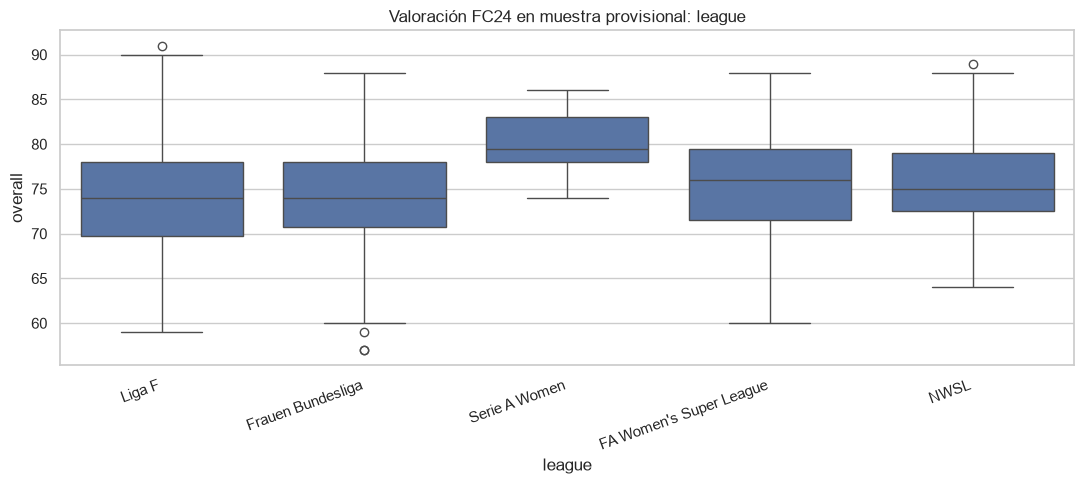

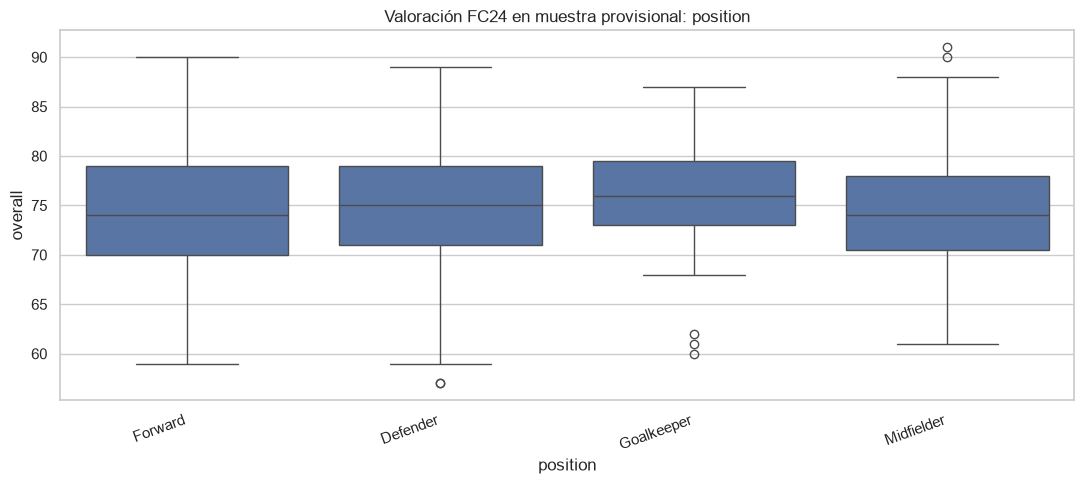

In [7]:
display(muestra.groupby(["league", "position"]).size().unstack(fill_value=0))
for grupo in ["league", "position"]:
    plt.figure(figsize=(11, 5))
    sns.boxplot(data=muestra, x=grupo, y="overall")
    plt.xticks(rotation=20, ha="right")
    plt.title("Valoración FC24 en muestra provisional: " + grupo)
    plt.tight_layout()
    plt.savefig("figuras/overall_" + grupo + ".png", dpi=140)
    plt.show()

### 7.2. Valoración y métricas específicas
Delanteras: xG, tiros por aparición y conversión con ≥20 tiros. Centrocampistas: pases a tiro, asistencias por aparición y precisión de pase. Defensas: entradas e intercepciones favorables por aparición. Porteras: paradas por aparición describen volumen de trabajo, **no calidad suficiente**; faltan tiros recibidos y dificultad.

Se muestran overall y un atributo relacionado del videojuego. La correlación de Spearman compara ordenaciones y reduce la dependencia de valores extremos; Pearson describe asociación lineal. Ninguna demuestra causalidad.

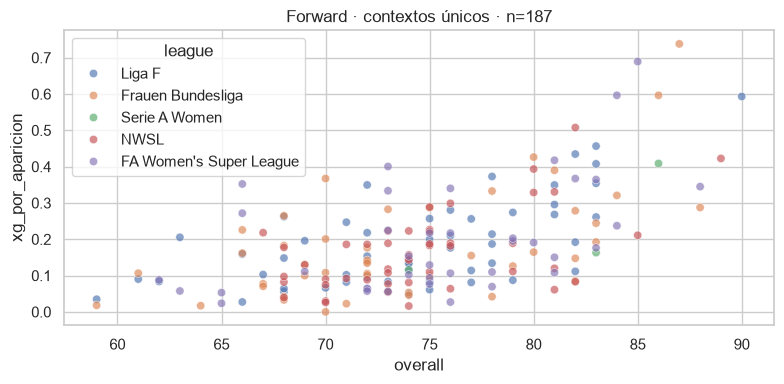

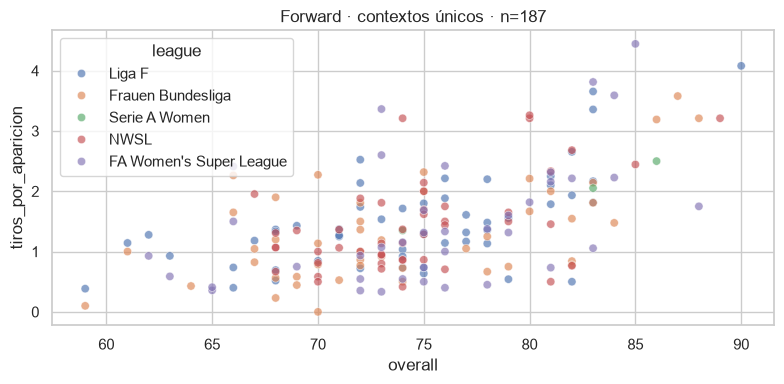

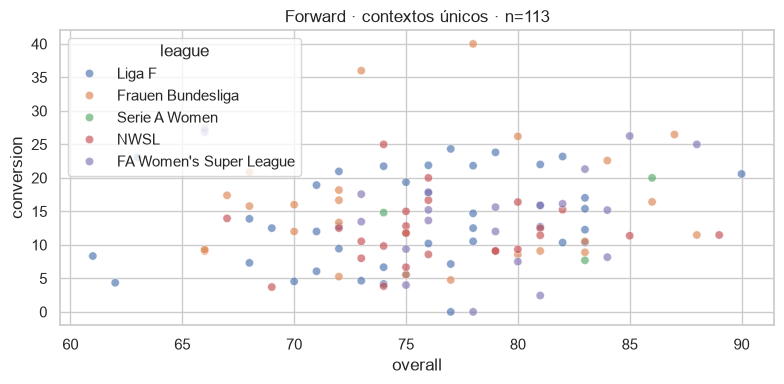

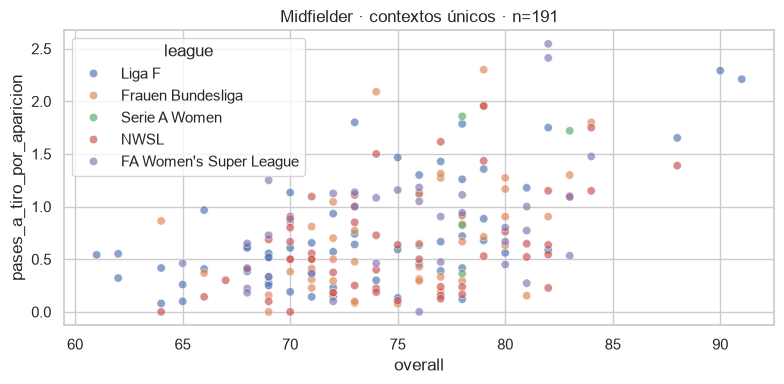

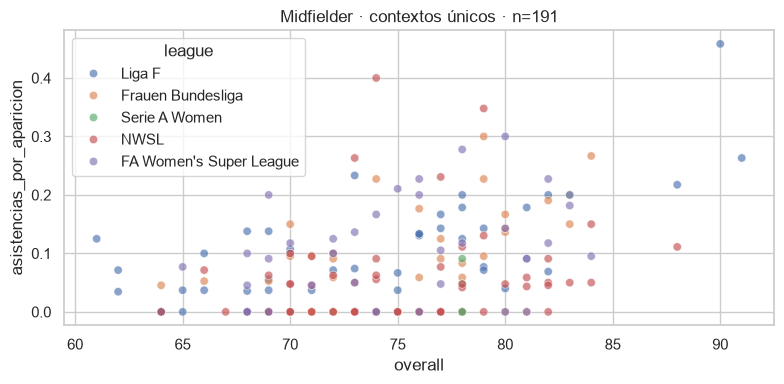

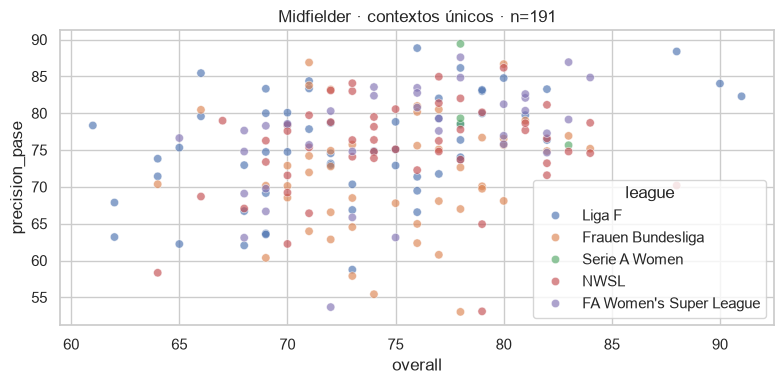

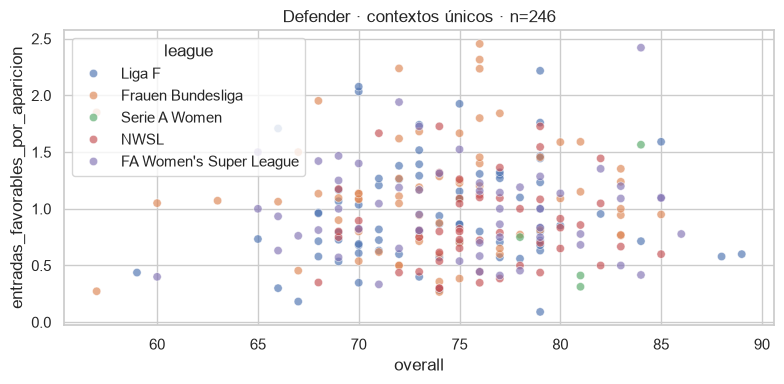

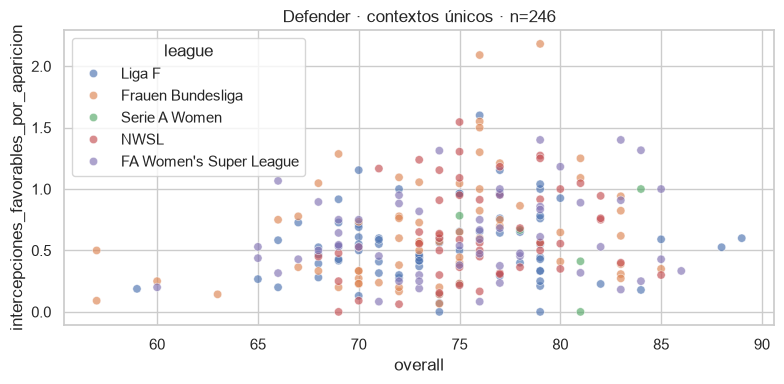

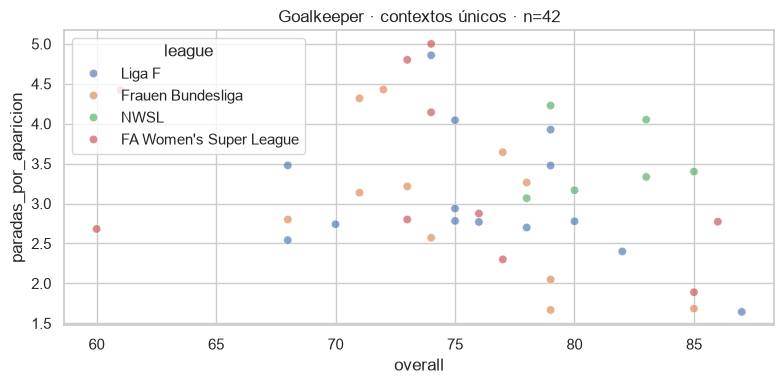

,posicion,metrica,valoracion,n,spearman,pearson
0,Forward,xg_por_aparicion,overall,187,0.516,0.568
1,Forward,xg_por_aparicion,shooting,187,0.496,0.538
2,Forward,tiros_por_aparicion,overall,187,0.490,0.550
3,Forward,tiros_por_aparicion,shooting,187,0.474,0.525
4,Forward,conversion,overall,113,0.123,0.116
5,Forward,conversion,shooting,113,0.167,0.131
6,Midfielder,pases_a_tiro_por_aparicion,overall,191,0.446,0.496
7,Midfielder,pases_a_tiro_por_aparicion,passing,191,0.465,0.504
8,Midfielder,asistencias_por_aparicion,overall,191,0.354,0.396
9,Midfielder,asistencias_por_aparicion,passing,191,0.348,0.353


In [8]:
comparaciones = [("Forward", "xg_por_aparicion", "shooting"), ("Forward", "tiros_por_aparicion", "shooting"), ("Forward", "conversion", "shooting"), ("Midfielder", "pases_a_tiro_por_aparicion", "passing"), ("Midfielder", "asistencias_por_aparicion", "passing"), ("Midfielder", "precision_pase", "passing"), ("Defender", "entradas_favorables_por_aparicion", "defending"), ("Defender", "intercepciones_favorables_por_aparicion", "defending"), ("Goalkeeper", "paradas_por_aparicion", "goalkeeping_reflexes")]
resultados = []
for posicion, metrica, atributo in comparaciones:
    datos = muestra[(muestra["position"] == posicion) & muestra["id_statsbomb"].isin(ids_contexto_unico)].copy()
    if metrica == "conversion":
        datos = datos[datos["tiros"] >= 20]
    for valoracion in ["overall", atributo]:
        pares = datos.dropna(subset=[metrica, valoracion])
        if len(pares) >= 3 and pares[metrica].nunique() > 1 and pares[valoracion].nunique() > 1:
            rho = pares[metrica].corr(pares[valoracion], method="spearman")
            pearson = pares[metrica].corr(pares[valoracion], method="pearson")
            resultados.append({"posicion": posicion, "metrica": metrica, "valoracion": valoracion, "n": len(pares), "spearman": rho, "pearson": pearson})
    plt.figure(figsize=(8, 4))
    sns.scatterplot(data=datos, x="overall", y=metrica, hue="league", alpha=0.65)
    plt.title(posicion + " · contextos únicos · n=" + str(datos.dropna(subset=["overall", metrica]).shape[0]))
    plt.tight_layout()
    plt.savefig("figuras/" + posicion + "_" + metrica + ".png", dpi=140)
    plt.show()
correlaciones = pd.DataFrame(resultados)
display(correlaciones.round(3))
correlaciones.to_csv("data/procesados/correlaciones_posicion.csv", index=False)

### 7.3. Diferencias entre ligas y sensibilidad
Calculamos asociaciones por liga y posición, indicando n. Solo mostramos correlación con al menos 10 pares y variación en ambas variables. Las medianas y cuartiles muestran asimetría. 

In [9]:
principales = [("Forward", "xg_por_aparicion"), ("Midfielder", "pases_a_tiro_por_aparicion"), ("Defender", "intercepciones_favorables_por_aparicion"), ("Goalkeeper", "paradas_por_aparicion")]
sensibilidad = []
por_liga = []
for posicion, metrica in principales:
    for umbral in [1, 5, 10]:
        datos = analisis[(analisis["position"] == posicion) & (analisis["partidos_jugados"] >= umbral) & analisis["id_statsbomb"].isin(ids_contexto_unico)]
        pares = datos.dropna(subset=["overall", metrica])
        rho = float("nan")
        if len(pares) >= 10 and pares[metrica].nunique() > 1 and pares["overall"].nunique() > 1:
            rho = pares["overall"].corr(pares[metrica], method="spearman")
        sensibilidad.append({"posicion": posicion, "min_apariciones": umbral, "n": len(pares), "spearman": rho})
    datos = muestra[(muestra["position"] == posicion) & muestra["id_statsbomb"].isin(ids_contexto_unico)]
    display(datos.groupby("league")[metrica].describe().round(3))
    for liga in completa["league"].unique():
        pares = datos[datos["league"] == liga].dropna(subset=["overall", metrica])
        rho = float("nan")
        if len(pares) >= 10 and pares[metrica].nunique() > 1 and pares["overall"].nunique() > 1:
            rho = pares["overall"].corr(pares[metrica], method="spearman")
        por_liga.append({"posicion": posicion, "liga": liga, "n": len(pares), "spearman": rho})
sensibilidad = pd.DataFrame(sensibilidad)
por_liga = pd.DataFrame(por_liga)
display(sensibilidad.round(3))
display(por_liga.round(3))
sensibilidad.to_csv("data/procesados/sensibilidad.csv", index=False)
por_liga.to_csv("data/procesados/correlaciones_liga.csv", index=False)

,count,mean,std,min,25%,50%,75%,max
league,,,,,,,,
FA Women's Super League,39.0,0.201,0.155,0.024,0.082,0.154,0.303,0.689
Frauen Bundesliga,46.0,0.180,0.151,0.000,0.079,0.140,0.260,0.738
Liga F,52.0,0.192,0.124,0.027,0.089,0.168,0.261,0.593
NWSL,47.0,0.165,0.107,0.016,0.086,0.147,0.215,0.508
Serie A Women,3.0,0.229,0.157,0.116,0.139,0.163,0.286,0.409


,count,mean,std,min,25%,50%,75%,max
league,,,,,,,,
FA Women's Super League,35.0,0.835,0.555,0.000,0.456,0.800,1.101,2.545
Frauen Bundesliga,46.0,0.707,0.554,0.000,0.298,0.566,0.905,2.300
Liga F,57.0,0.734,0.543,0.080,0.370,0.586,0.967,2.292
NWSL,49.0,0.652,0.487,0.000,0.238,0.545,0.917,1.957
Serie A Women,4.0,1.191,0.717,0.364,0.709,1.272,1.754,1.857


,count,mean,std,min,25%,50%,75%,max
league,,,,,,,,
FA Women's Super League,54.0,0.624,0.340,0.083,0.376,0.536,0.876,1.400
Frauen Bundesliga,65.0,0.657,0.448,0.067,0.333,0.571,0.824,2.182
Liga F,72.0,0.536,0.298,0.000,0.329,0.513,0.663,1.600
NWSL,50.0,0.656,0.379,0.000,0.364,0.562,0.949,1.545
Serie A Women,5.0,0.572,0.384,0.000,0.412,0.667,0.783,1.000


,count,mean,std,min,25%,50%,75%,max
league,,,,,,,,
FA Women's Super League,10.0,3.368,1.113,1.889,2.705,2.838,4.352,5.000
Frauen Bundesliga,11.0,2.979,0.947,1.667,2.310,3.136,3.453,4.429
Liga F,15.0,3.160,0.842,1.643,2.720,2.783,3.702,4.857
NWSL,6.0,3.541,0.481,3.067,3.208,3.367,3.887,4.227


,posicion,min_apariciones,n,spearman
0,Forward,1,229,0.541
1,Forward,5,217,0.534
2,Forward,10,187,0.516
3,Midfielder,1,232,0.503
4,Midfielder,5,215,0.481
5,Midfielder,10,191,0.446
6,Defender,1,312,0.170
7,Defender,5,280,0.208
8,Defender,10,246,0.203
9,Goalkeeper,1,82,-0.038


,posicion,liga,n,spearman
0,Forward,Liga F,52,0.588
1,Forward,Frauen Bundesliga,46,0.506
2,Forward,NWSL,47,0.458
3,Forward,Serie A Women,3,NaN
4,Forward,FA Women's Super League,39,0.528
5,Midfielder,Liga F,57,0.552
6,Midfielder,Frauen Bundesliga,46,0.420
7,Midfielder,NWSL,49,0.382
8,Midfielder,Serie A Women,4,NaN
9,Midfielder,FA Women's Super League,35,0.390


### 7.4. Casos discordantes para investigar
Dentro de cada liga y posición buscamos coincidencias entre cuartil alto de overall y cuartil bajo de una métrica, y el caso inverso. En porteras, mayor volumen de paradas no equivale a mejor rendimiento.

In [10]:
casos = []
for posicion, metrica in principales:
    for liga in muestra["league"].unique():
        datos = muestra[(muestra["position"] == posicion) & (muestra["league"] == liga) & muestra["id_statsbomb"].isin(ids_contexto_unico)].dropna(subset=["overall", metrica]).copy()
        if len(datos) >= 20 and datos[metrica].nunique() > 1 and datos["overall"].nunique() > 1:
            alto_fc = datos["overall"].quantile(0.75)
            bajo_fc = datos["overall"].quantile(0.25)
            alto_deporte = datos[metrica].quantile(0.75)
            bajo_deporte = datos[metrica].quantile(0.25)
            seleccion = datos[((datos["overall"] >= alto_fc) & (datos[metrica] <= bajo_deporte)) | ((datos["overall"] <= bajo_fc) & (datos[metrica] >= alto_deporte))].copy()
            seleccion["metrica_examinada"] = metrica
            seleccion["valor_observado"] = seleccion[metrica]
            casos.append(seleccion[["id_statsbomb", "id_fc24", "player_name", "team", "club_name", "league", "position", "partidos_jugados", "overall", "metrica_examinada", "valor_observado"]])
casos = pd.concat(casos, ignore_index=True)
display(casos.round(3))
casos.to_csv("data/procesados/casos_para_revisar.csv", index=False)

,id_statsbomb,id_fc24,player_name,team,club_name,league,position,partidos_jugados,overall,metrica_examinada,valor_observado
0,49832,253437,Marta Cardona De Miguel,Atletico Madrid W,Atletico Madrid W,Liga F,Forward,24,79,xg_por_aparicion,0.087
1,409196,277123,Carlota Suárez Crespo,Granada W,Granada W,Liga F,Forward,27,68,xg_por_aparicion,0.262
2,408970,276937,Vanessa Haim,Nürnberg W,Nürnberg W,Frauen Bundesliga,Forward,20,68,xg_por_aparicion,0.265
3,81580,270407,Agnes Beever-Jones,Chelsea FCW,Chelsea W,FA Women's Super League,Forward,17,66,xg_por_aparicion,0.352
4,5086,267269,Rachel Hill,San Diego Wave,San Diego Wave W,NWSL,Forward,18,81,xg_por_aparicion,0.061
5,13881,226973,Eva Sofia Jakobsson,San Diego Wave,San Diego Wave W,NWSL,Forward,17,82,xg_por_aparicion,0.083
6,389492,273486,Messiah Bright,Orlando Pride,Orlando Pride W,NWSL,Forward,22,67,xg_por_aparicion,0.218
7,10126,228565,Clarisse Le Bihan,Angel City,Angel City W,NWSL,Forward,17,76,xg_por_aparicion,0.064
8,49900,272202,Iris Arnaiz Gil,Real Sociedad de Fútbol,Real Sociedad W,Liga F,Midfielder,25,78,pases_a_tiro_por_aparicion,0.120
9,409185,275774,Alicia Redondo González,Granada W,Granada W,Liga F,Midfielder,30,66,pases_a_tiro_por_aparicion,0.967


### 7.5. Lectura de las salidas comprobadas y límites
La ejecución confirma 1.739 IDs deportivos, 1.791 contextos y ninguna clave deportiva duplicada. Hay 1.580 filas con participación y 211 sin ella. FC24 contiene 1.839 IDs, todos de edición 24 y fecha 22/09/2023.

El cruce reconstruye los 1.047 IDs con jugadora única. Sus recuentos por liga son WSL 217, Bundesliga 260, Liga F 305, NWSL 247 y Serie A 31. Con la regla quedan 933 identidades provisionales: 960 filas deportivas enlazadas, de las cuales 903 tienen participación. La muestra de ≥10 apariciones tiene 682 filas (excluye 221 de las 903). Las correlaciones eliminan otras 16 filas.

La cobertura provisional sobre filas completas es WSL 60,4 %, Bundesliga 75,8 %, Liga F 53,3 %, NWSL 67,6 % y Serie A 6,8 %. Esta selección desigual impide generalizar a todas las futbolistas o interpretar las diferencias entre ligas como comparaciones equilibradas.

En personas de contexto único con ≥10 apariciones, overall y xG por aparición en delanteras tienen Spearman 0,516 (n=187); overall y pases a tiro en centrocampistas, 0,446 (n=191). La conversión de delanteras con ≥20 tiros muestra una asociación menor: 0,123 (n=113). En defensas, entradas favorables por aparición muestra 0,034 (n=246), frente a 0,203 para intercepciones favorables. 

En porteras, overall y paradas por aparición tienen Spearman −0,340 (n=42). No significa que parar más sea jugar peor: es volumen condicionado por tiros recibidos y contexto del equipo. Además cambia de −0,038 con ≥1 aparición (n=82) a −0,340 con ≥10; la selección de participación importa.

Se exportan 43 casos extremos de cuartiles para investigar; no se etiquetan como sobrevaloradas o infravaloradas. Queda pendiente revisar individualmente los clubes y las identidades, resolver candidatos ambiguos y comprobar sesgos. 